# Part I — Task 2: Controlled NumPy/PyTorch comparison

The NumPy reference is bundled from Assignment 1. Both models use 2 → 20 → 2, ReLU, SGD with learning rate 0.01, float64, identical initial parameters and identical batch permutations. NumPy includes softmax; PyTorch returns logits for `CrossEntropyLoss`.

The prespecified study uses 1,500 **epochs**, seeds 42/43/44, full-batch and mini-batch size 32, on `make_moons` (noise 0.2) and `make_circles` (noise 0.1, factor 0.5). Each dataset contains 1,000 examples with a stratified 800/200 split. Seed changes affect both the data and initialization: the reported standard deviation combines these sources of variation.

**Budget limitation:** 1,500 full-batch epochs mean 1,500 updates; 1,500 mini-batch epochs mean 37,500 updates. Framework comparisons are matched exactly within each setting. Cross-strategy accuracy does not establish an advantage at equal update count or wall time. Test curves are descriptive; no hyperparameter selection uses these test sets.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
PART = Path.cwd() if (Path.cwd() / 'compare_mlp.py').exists() else Path.cwd() / 'Part 1'
sys.path.insert(0, str(PART.resolve()))
from compare_mlp import run_study, verify_parity
from pytorch_mlp import MLP
torch.set_num_threads(1)
RUN_STUDY = False  # Explicit opt-in: rerunning analysis does not retrain.
STUDY = PART / 'results/comparison/study-rtwiiv3n'
if RUN_STUDY:
    STUDY = run_study()
summary = json.loads((STUDY / 'summary.json').read_text())
assert summary['status'] == 'complete'
results = {r['run']: json.loads((STUDY / r['run'] / 'history.json').read_text()) for r in summary['records']}
print('Evidence directory:', STUDY)
print('Fresh numerical check:', verify_parity())
print('Saved numerical check:', summary['parity'])

Evidence directory: <assignment-root>/Part 1/results/comparison/study-rtwiiv3n
Fresh numerical check: {'probability_max_abs': 5.551115123125783e-17, 'loss_abs': 0.0, 'gradient_max_abs': 4.163336342344337e-17, 'update_max_abs': 4.336808689942018e-19}
Saved numerical check: {'probability_max_abs': 5.551115123125783e-17, 'loss_abs': 0.0, 'gradient_max_abs': 4.163336342344337e-17, 'update_max_abs': 4.336808689942018e-19}


## Parameter and matrix dimensions

| Operation | Parameters | Input → output |
|---|---|---|
| Linear 1 | W: (20,2), b: (20), 60 scalars | (B,2) → (B,20) |
| ReLU | none | (B,20) → (B,20) |
| Linear 2 | W: (2,20), b: (2), 42 scalars | (B,20) → (B,2) |
| Mean cross-entropy | integer targets (B,) | (B,2) → scalar |

Total: **102 trainable parameters**. NumPy stores the transpose of each PyTorch weight. Backpropagation starts with `(softmax(logits) - one_hot_targets)/B`. For a NumPy affine layer, `dW = X.T @ dZ`, `db = dZ.sum(axis=0)`, and `dX = dZ @ W.T`. SGD updates every parameter by `theta -= 0.01 * gradient`.

The original NumPy loss clips probabilities at 1e-12, while its backward formula differentiates unclipped softmax cross-entropy. We preserve that reference implementation and explicitly check whether clipping was encountered.

In [2]:
rows = ['| Data | Batch | Seed | Updates | NumPy test | PyTorch test | Max parameter difference |', '|---|---:|---:|---:|---:|---:|---:|']
for r in results.values():
    rows.append(f"| {r['dataset']} | {r['batch_size'] or 'full'} | {r['seed']} | {r['pytorch']['updates'][-1]} | {r['numpy']['test_accuracy'][-1]:.2%} | {r['pytorch']['test_accuracy'][-1]:.2%} | {r['parameter_max_abs']:.2e} |")
display(Markdown('\n'.join(rows)))
print('Maximum loss trajectory difference:', max(r['loss_max_abs'] for r in results.values()))
print('Minimum observed true-class probability:', min(r['minimum_true_class_probability'] for r in results.values()))
assert not any(r['clipping_active'] for r in results.values())
for dataset in ['moons', 'circles']:
    for batch in [0, 32]:
        values = [r['pytorch']['test_accuracy'][-1] for r in results.values() if r['dataset']==dataset and r['batch_size']==batch]
        print(f'{dataset}, batch={batch or "full"}: {np.mean(values):.2%} ± {np.std(values, ddof=1):.2%} (sample SD, n=3)')

| Data | Batch | Seed | Updates | NumPy test | PyTorch test | Max parameter difference |
|---|---:|---:|---:|---:|---:|---:|
| moons | full | 42 | 1500 | 87.00% | 87.00% | 2.78e-16 |
| moons | full | 43 | 1500 | 81.00% | 81.00% | 2.78e-16 |
| moons | full | 44 | 1500 | 85.50% | 85.50% | 3.89e-16 |
| moons | 32 | 42 | 37500 | 94.50% | 94.50% | 2.28e-15 |
| moons | 32 | 43 | 37500 | 83.50% | 83.50% | 2.22e-15 |
| moons | 32 | 44 | 37500 | 89.50% | 89.50% | 1.67e-15 |
| circles | full | 42 | 1500 | 64.00% | 64.00% | 1.04e-17 |
| circles | full | 43 | 1500 | 71.50% | 71.50% | 1.39e-17 |
| circles | full | 44 | 1500 | 76.50% | 76.50% | 9.05e-18 |
| circles | 32 | 42 | 37500 | 99.50% | 99.50% | 1.11e-15 |
| circles | 32 | 43 | 37500 | 99.50% | 99.50% | 1.33e-15 |
| circles | 32 | 44 | 37500 | 99.00% | 99.00% | 1.78e-15 |

Maximum loss trajectory difference: 3.3306690738754696e-16
Minimum observed true-class probability: 0.014364452389731793
moons, batch=full: 84.50% ± 3.12% (sample SD, n=3)
moons, batch=32: 89.17% ± 5.51% (sample SD, n=3)
circles, batch=full: 70.67% ± 6.29% (sample SD, n=3)
circles, batch=32: 99.33% ± 0.29% (sample SD, n=3)


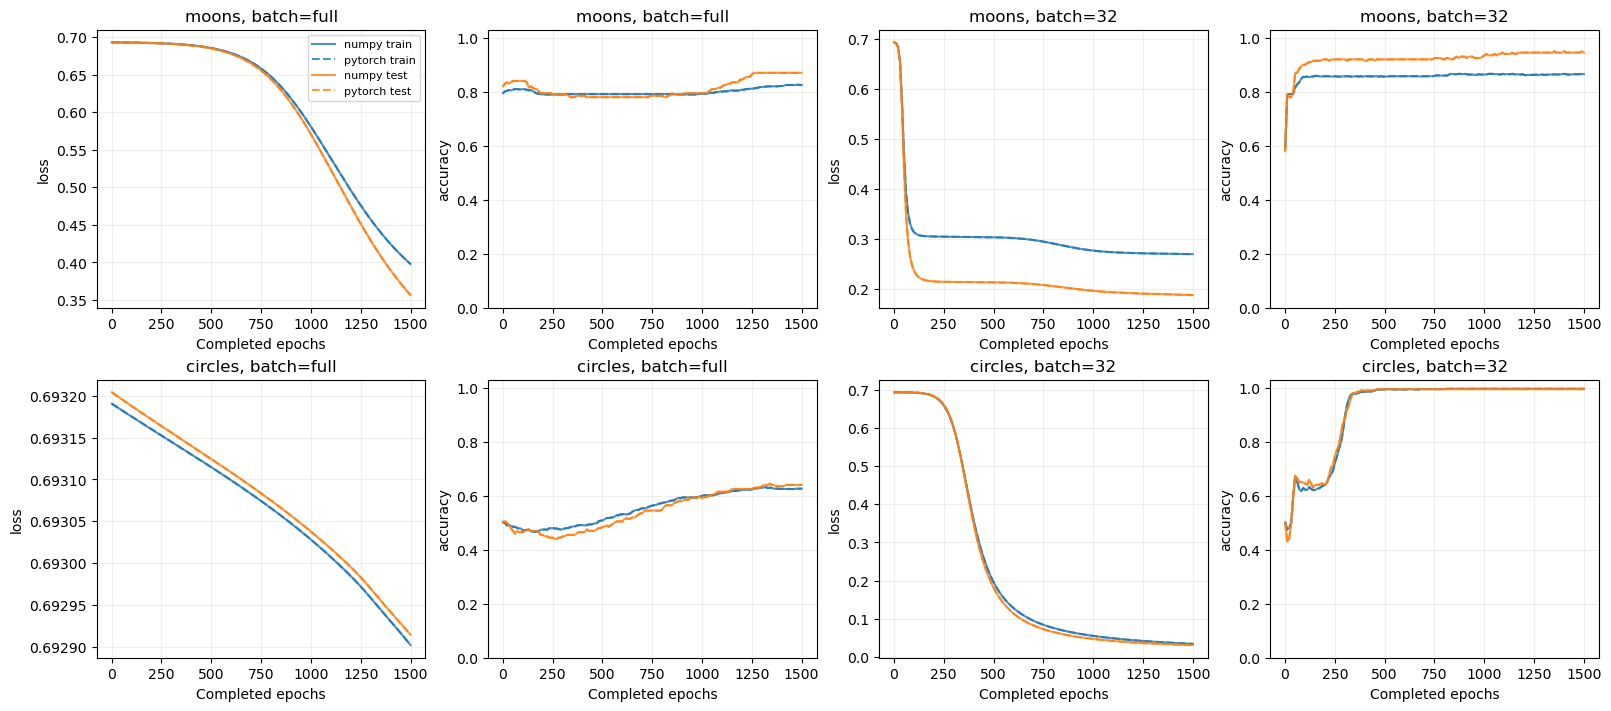

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for row, dataset in enumerate(['moons', 'circles']):
    for column, batch in enumerate([0, 32]):
        r = next(r for r in results.values() if r['dataset']==dataset and r['batch_size']==batch and r['seed']==42)
        for metric_i, metric in enumerate(['loss', 'accuracy']):
            ax = axes[row, column*2+metric_i]
            for split, color in [('train', 'tab:blue'), ('test', 'tab:orange')]:
                for framework, style in [('numpy', '-'), ('pytorch', '--')]:
                    h = r[framework]
                    ax.plot(h['epochs'], h[f'{split}_{metric}'], style, color=color, label=f'{framework} {split}', alpha=0.8)
            ax.set(title=f'{dataset}, batch={batch or "full"}', xlabel='Completed epochs', ylabel=metric)
            if metric=='accuracy': ax.set_ylim(0, 1.03)
            ax.grid(alpha=0.2)
axes[0,0].legend(fontsize=8)
fig.savefig(STUDY/'learning_curves.png', dpi=160)
plt.show()

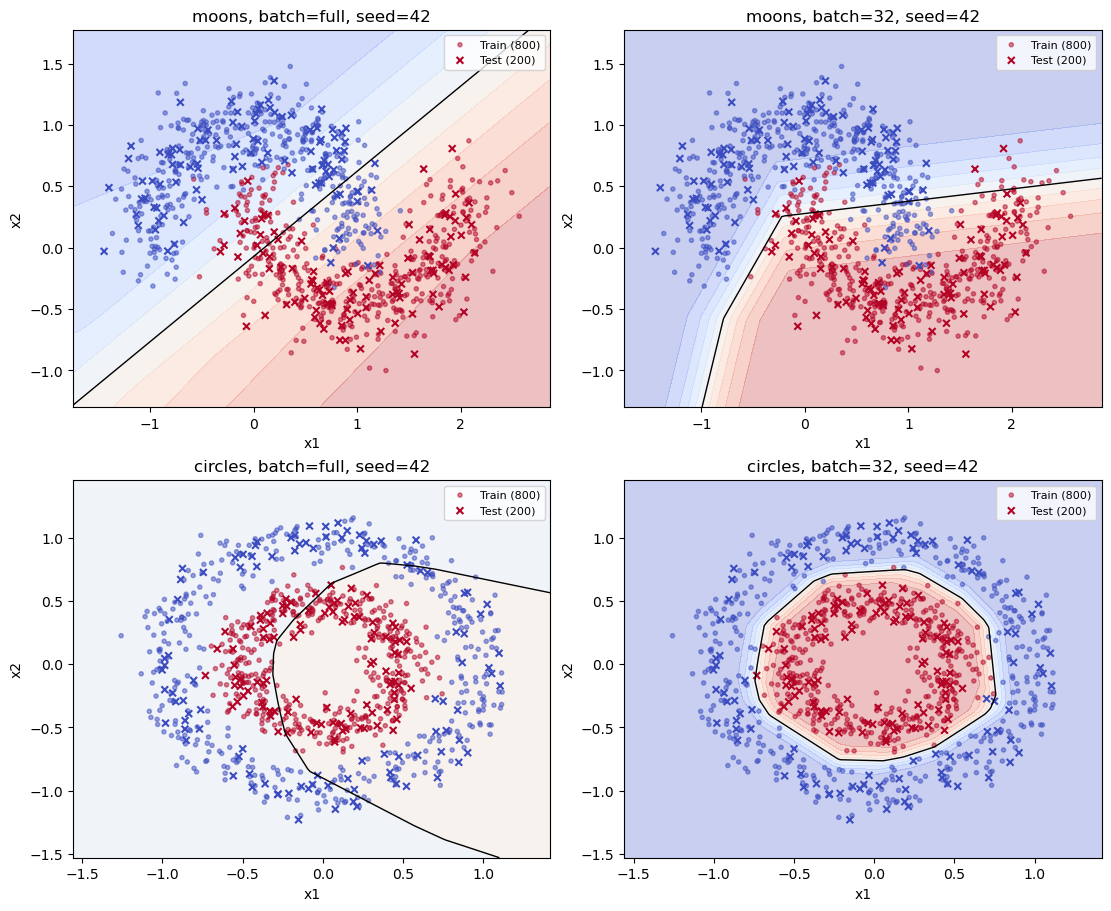

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
for row, dataset in enumerate(['moons', 'circles']):
    for column, batch in enumerate([0, 32]):
        name = f'{dataset}-batch{batch}-seed42'
        data = np.load(STUDY/name/'data.npz')
        model = MLP(2,[20],2).double().eval()
        model.load_state_dict(torch.load(STUDY/name/'model.pt', map_location='cpu', weights_only=True))
        all_x=np.concatenate([data['x_train'],data['x_test']])
        low, high=all_x.min(0)-0.3, all_x.max(0)+0.3
        xx,yy=np.meshgrid(np.linspace(low[0],high[0],180),np.linspace(low[1],high[1],180))
        with torch.no_grad():
            p=model(torch.from_numpy(np.c_[xx.ravel(),yy.ravel()])).softmax(1)[:,1].numpy().reshape(xx.shape)
        ax=axes[row,column]
        ax.contourf(xx,yy,p,levels=np.linspace(0,1,11),cmap='coolwarm',alpha=0.3,vmin=0,vmax=1)
        ax.contour(xx,yy,p,levels=[0.5],colors='black',linewidths=1)
        ax.scatter(*data['x_train'].T,c=data['y_train'],cmap='coolwarm',s=9,alpha=0.5,label='Train (800)')
        ax.scatter(*data['x_test'].T,c=data['y_test'],cmap='coolwarm',s=24,marker='x',label='Test (200)')
        ax.set(title=f'{dataset}, batch={batch or "full"}, seed=42',xlabel='x1',ylabel='x2')
        ax.legend(fontsize=8)
fig.savefig(STUDY/'decision_boundaries.png',dpi=160)
plt.show()

In [5]:
maximum=max(r['parameter_max_abs'] for r in results.values())
display(Markdown(f"""## Evidence-based interpretation

Across all 12 paired settings, the largest final parameter difference was **{maximum:.2e}**. Together with the forward/loss/gradient/single-update checks, this supports numerical equivalence for these tested configurations; it does not prove equivalence for arbitrary extreme logits.

The full-batch circles models remain substantially worse than the mini-batch models at the fixed epoch budget. The mini-batch models receive 25 times as many updates. Small initial weights (standard deviation 0.01) and optimization dynamics are possible explanations for slow early learning; this study does not isolate their effects.

Moons accuracy varies across seeds, so the seed-42 result alone is not a reliability estimate. The plotted boundaries show what each fitted classifier learned. The timing fields are implementation-specific CPU observations with sequential execution, not a general framework speed benchmark.
"""))

## Evidence-based interpretation

Across all 12 paired settings, the largest final parameter difference was **2.28e-15**. Together with the forward/loss/gradient/single-update checks, this supports numerical equivalence for these tested configurations; it does not prove equivalence for arbitrary extreme logits.

The full-batch circles models remain substantially worse than the mini-batch models at the fixed epoch budget. The mini-batch models receive 25 times as many updates. Small initial weights (standard deviation 0.01) and optimization dynamics are possible explanations for slow early learning; this study does not isolate their effects.

Moons accuracy varies across seeds, so the seed-42 result alone is not a reliability estimate. The plotted boundaries show what each fitted classifier learned. The timing fields are implementation-specific CPU observations with sequential execution, not a general framework speed benchmark.
